# 02 - Keşif Analizi ve Görselleştirme

**Sorumlu:** Aybüke Gökçe Yavaş

**Ödevdeki karşılığı:** 3. Veri Analizi

In [2]:
# KURULUM: bu hucreyi her oturumun basinda bir kez calistir.
# Repoyu Colab'e indirir; boylece src/ortak.py kullanilabilir.
import os
REPO_URL = "https://github.com/zeyneppbaran/ml-proje.git"  # TODO: kendi repo adresiniz
if not os.path.exists("/content/ml-proje"):
    !git clone {REPO_URL} /content/ml-proje
else:
    !git -C /content/ml-proje pull
%cd /content/ml-proje

Already up to date.
c:\content\ml-proje


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.ortak import veri_yukle

df = veri_yukle()
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,daha_once_aranmis
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0


## C1. Hedef değişkenin dağılımı

Sınıf Sayıları:
y
0    36548
1     4640
Name: count, dtype: int64

Sınıf Oranları (%):
y
0    88.73
1    11.27
Name: proportion, dtype: float64

Dengesizlik Oranı (no/yes): 7.88


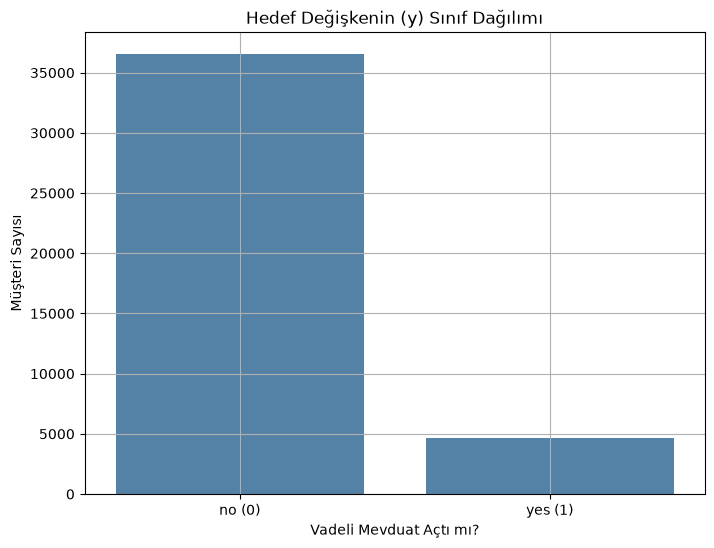

In [2]:
# 1. Hedef değişkenin (y) sınıf sayılarını ve oranlarını hesaplıyoruz
sinif_sayilari = df['y'].value_counts()
sinif_oranlari = df['y'].value_counts(normalize=True) * 100

print("Sınıf Sayıları:")
print(sinif_sayilari)
print("\nSınıf Oranları (%):")
print(sinif_oranlari.round(2))

# 2. Dengesizlik oranı: her 'yes' müşteriye kaç 'no' müşteri düşüyor?
dengesizlik_orani = sinif_sayilari[0] / sinif_sayilari[1]
print(f"\nDengesizlik Oranı (no/yes): {dengesizlik_orani:.2f}")

# 3. Sınıf dağılımını countplot ile görselleştiriyoruz
plt.figure(figsize=(8, 6))
sns.countplot(x='y', data=df, color='steelblue')
plt.title("Hedef Değişkenin (y) Sınıf Dağılımı")
plt.xticks([0, 1], ['no (0)', 'yes (1)'])
plt.xlabel("Vadeli Mevduat Açtı mı?")
plt.ylabel("Müşteri Sayısı")
plt.grid(True)
plt.savefig("figures/c1_hedef_dagilimi.png", dpi=150, bbox_inches='tight')
plt.show()

Yorum: Veri setinde 36.548 müşteri (%88,73) vadeli mevduat açmamış, sadece 4.640 müşteri (%11,27) açmıştır. Dengesizlik oranı 7,88'dir, yani her "yes" için yaklaşık 8 "no" vardır. Bu nedenle her müşteriye "no" diyen bir model bile %88 doğruluk elde eder, accuracy tek başına yanıltıcıdır. Modelleri değerlendirirken F1 ve ROC-AUC gibi metrikler kullanılmalı, veri bölünürken stratify ile sınıf oranı korunmalı ve gerekirse dengeleme yöntemleri uygulanmalıdır.

## C2. Sayısal özellikler: histogram ve boxplot

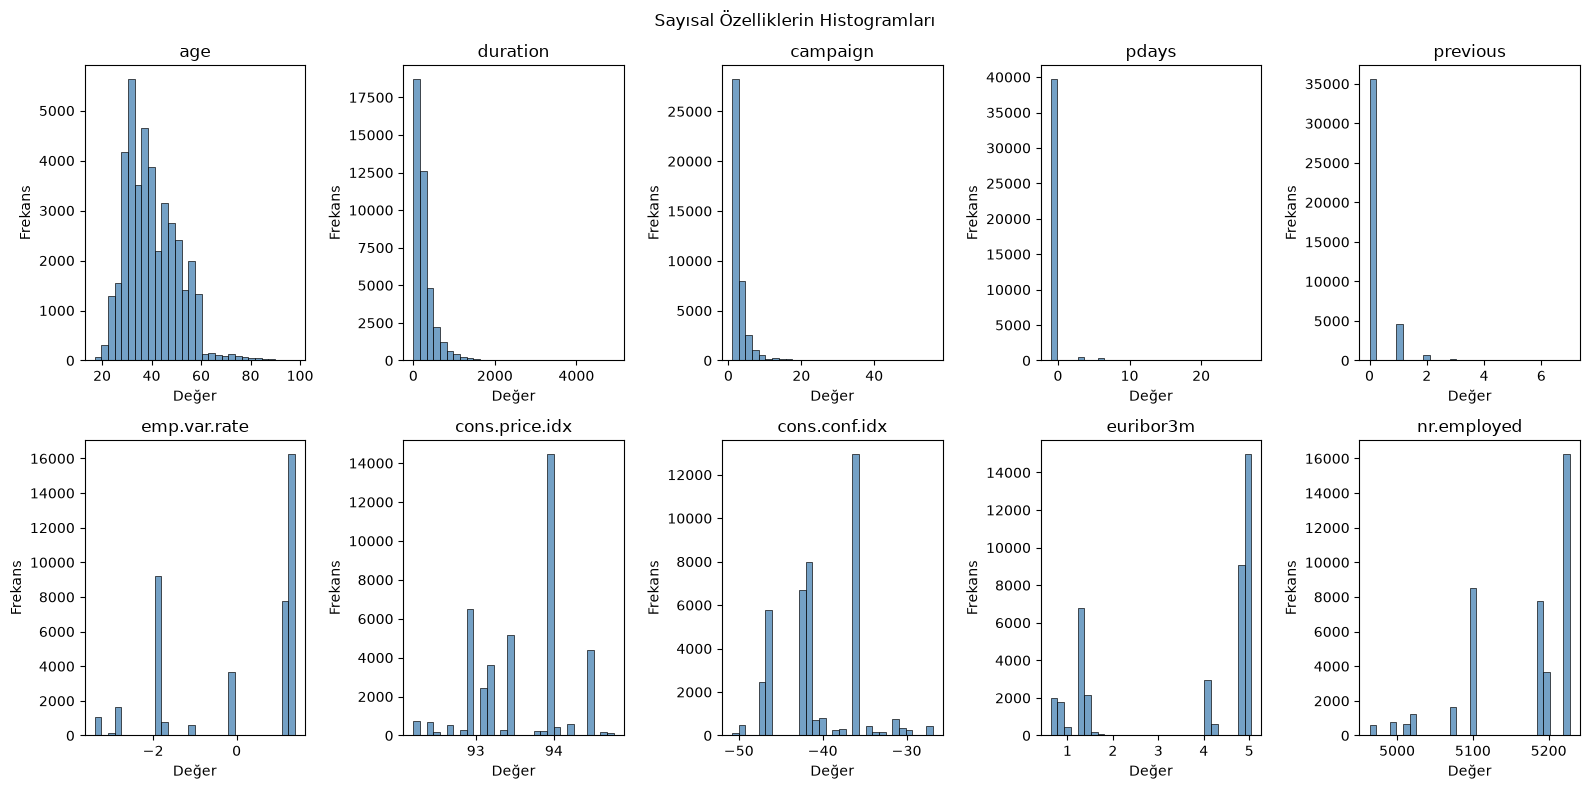

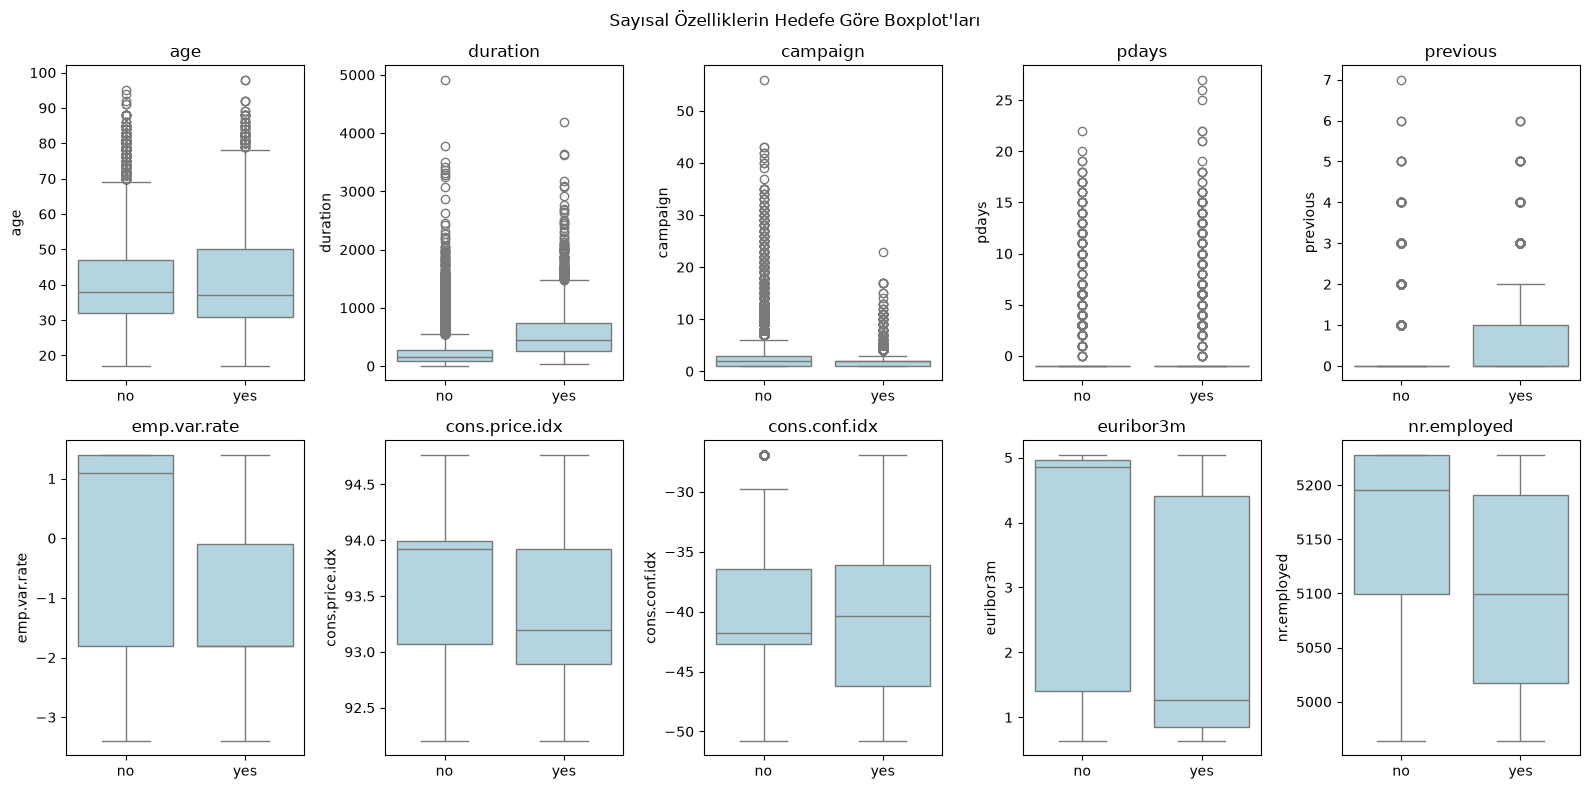

         Sütun  Alt Sınır  Üst Sınır  Aykırı Sayısı  Aykırı Oranı (%)
           age       9.50      69.50            469              1.14
      duration    -223.50     644.50           2963              7.19
      campaign      -2.00       6.00           2406              5.84
         pdays      -1.00      -1.00           1515              3.68
      previous       0.00       0.00           5625             13.66
  emp.var.rate      -6.60       6.20              0              0.00
cons.price.idx      91.70      95.37              0              0.00
 cons.conf.idx     -52.15     -26.95            447              1.09
     euribor3m      -4.08      10.39              0              0.00
   nr.employed    4905.60    5421.60              0              0.00


In [3]:
# 1. İncelenecek sayısal sütunlar
# (duration modelden çıkarıldı ama dağılımını görmek için burada gösteriyoruz)
sayisal_sutunlar = ['age', 'duration', 'campaign', 'pdays', 'previous',
                    'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
                    'euribor3m', 'nr.employed']

# 2. Histogramlar
plt.figure(figsize=(16, 8))
for i, sutun in enumerate(sayisal_sutunlar):
    plt.subplot(2, 5, i + 1)
    sns.histplot(df[sutun], bins=30, color='steelblue')
    plt.title(sutun)
    plt.xlabel("Değer")
    plt.ylabel("Frekans")
plt.suptitle("Sayısal Özelliklerin Histogramları")
plt.tight_layout()
plt.savefig("figures/c2_histogramlar.png", dpi=150, bbox_inches='tight')
plt.show()

# 3. Hedefe göre boxplot'lar (no ve yes müşterileri yan yana)
plt.figure(figsize=(16, 8))
for i, sutun in enumerate(sayisal_sutunlar):
    plt.subplot(2, 5, i + 1)
    sns.boxplot(x='y', y=sutun, data=df, color='lightblue')
    plt.title(sutun)
    plt.xticks([0, 1], ['no', 'yes'])
    plt.xlabel("")
plt.suptitle("Sayısal Özelliklerin Hedefe Göre Boxplot'ları")
plt.tight_layout()
plt.savefig("figures/c2_boxplotlar.png", dpi=150, bbox_inches='tight')
plt.show()

# 4. IQR yöntemiyle aykırı değer sayısı
aykiri_sonuclar = []
for sutun in sayisal_sutunlar:
    Q1 = df[sutun].quantile(0.25)
    Q3 = df[sutun].quantile(0.75)
    IQR = Q3 - Q1
    alt_sinir = Q1 - 1.5 * IQR
    ust_sinir = Q3 + 1.5 * IQR
    aykiri_sayisi = ((df[sutun] < alt_sinir) | (df[sutun] > ust_sinir)).sum()
    aykiri_sonuclar.append([sutun, alt_sinir, ust_sinir, aykiri_sayisi,
                            aykiri_sayisi / len(df) * 100])

aykiri_df = pd.DataFrame(aykiri_sonuclar, columns=['Sütun', 'Alt Sınır', 'Üst Sınır',
                                                   'Aykırı Sayısı', 'Aykırı Oranı (%)'])
print(aykiri_df.round(2).to_string(index=False))

**Yorum:** duration en ayırt edici sütun: "yes" müşterilerinde medyan 449 sn, "no"larda 163 sn. Ancak görüşme süresi arama bitince öğrenildiği için modelden çıkarıldı (veri sızıntısı). campaign ve previous sağa çarpıktır ve IQR'a göre aykırı değer içerir (%5,8 ve %13,7). pdays'deki -1 yığılması aykırı değer değil, "daha önce aranmadı" özel kodudur (%96). Ekonomik göstergelerde (emp.var.rate, euribor3m, nr.employed) "yes" grubu belirgin şekilde düşüktür; faizler düşükken müşteriler daha çok mevduat açmıştır. Aykırı değerler gerçek müşteri davranışı olduğu için silinmemiştir; XGBoost gibi ağaç modelleri bunlardan az etkilenir.

## C3. Kategorik özelliklerin hedefe göre dağılımı

Genel 'yes' oranı: %11.27


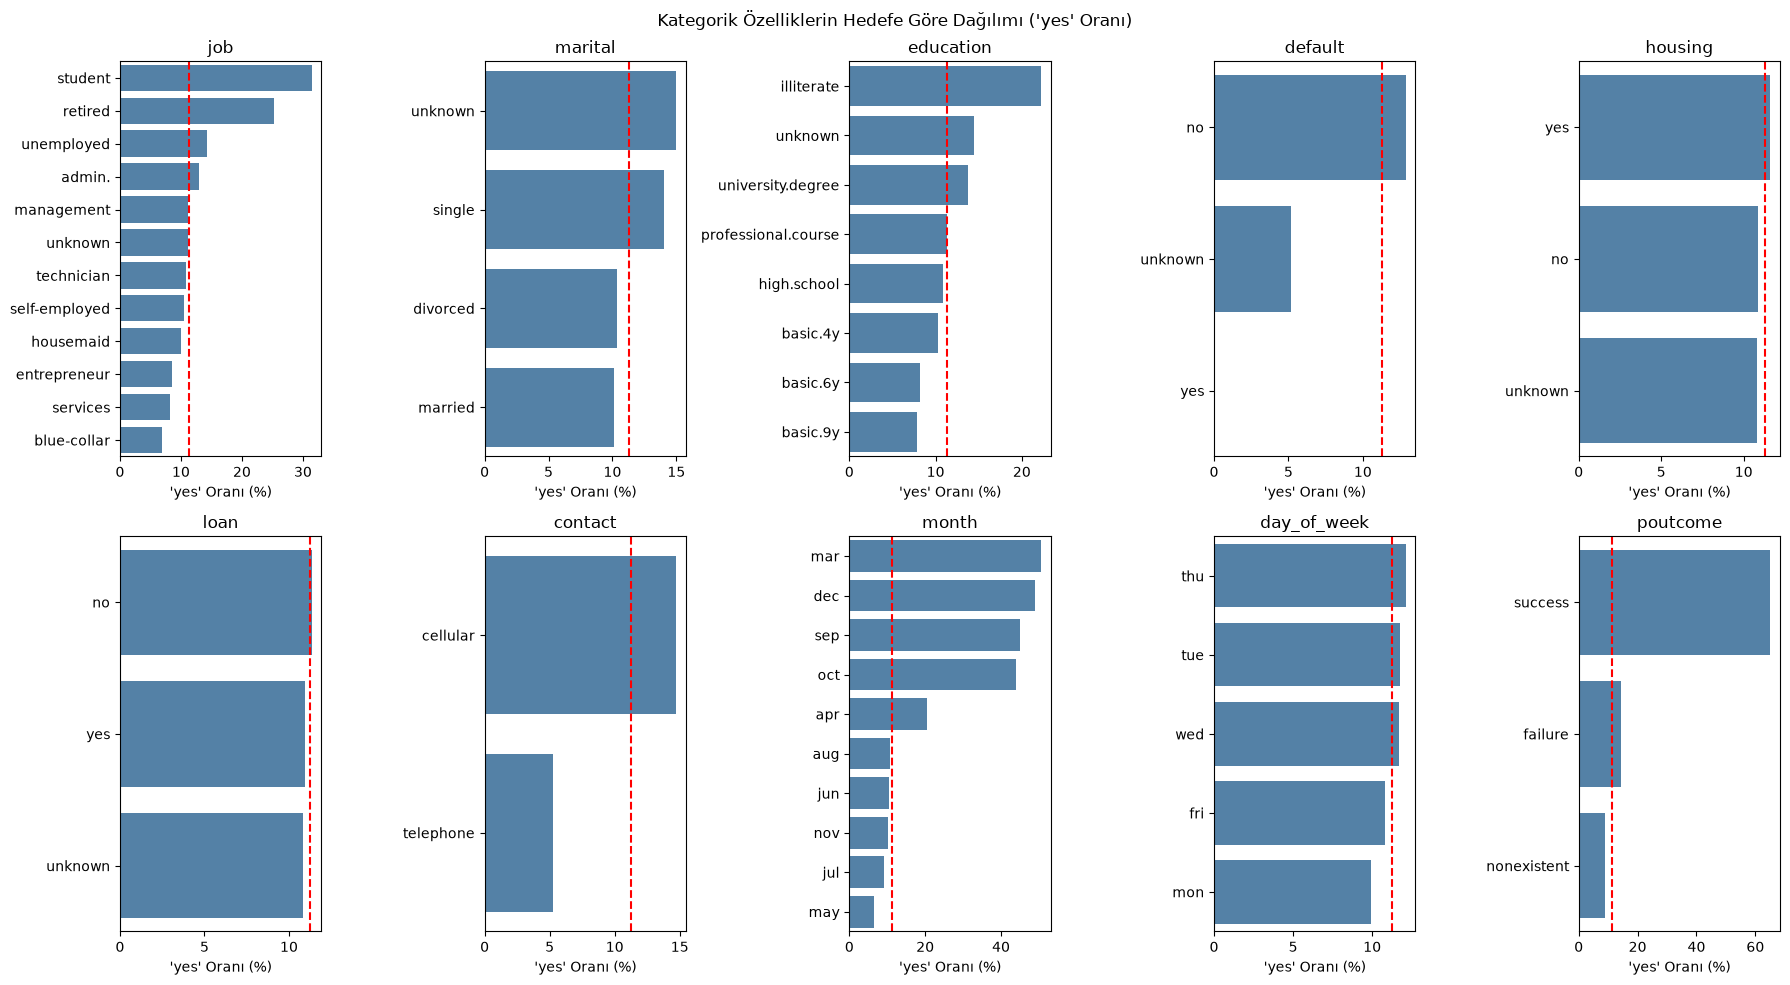

job          -> en yüksek: student (%31.4), en düşük: blue-collar (%6.9)
marital      -> en yüksek: unknown (%15.0), en düşük: married (%10.2)
education    -> en yüksek: illiterate (%22.2), en düşük: basic.9y (%7.8)
default      -> en yüksek: no (%12.9), en düşük: yes (%0.0)
housing      -> en yüksek: yes (%11.6), en düşük: unknown (%10.8)
loan         -> en yüksek: no (%11.3), en düşük: unknown (%10.8)
contact      -> en yüksek: cellular (%14.7), en düşük: telephone (%5.2)
month        -> en yüksek: mar (%50.5), en düşük: may (%6.4)
day_of_week  -> en yüksek: thu (%12.1), en düşük: mon (%9.9)
poutcome     -> en yüksek: success (%65.1), en düşük: nonexistent (%8.8)


In [4]:
# 1. İncelenecek kategorik sütunlar
kategorik_sutunlar = ['job', 'marital', 'education', 'default', 'housing',
                      'loan', 'contact', 'month', 'day_of_week', 'poutcome']

# veri_yukle() bazı 'unknown' değerlerini NaN yaptı; grafikte görünsünler diye
# sadece bu kopyada geri yazıyoruz (asıl df değişmiyor)
df_kategorik = df[kategorik_sutunlar + ['y']].fillna('unknown')

# 2. Genel 'yes' oranı (karşılaştırma çizgisi için)
genel_oran = df['y'].mean() * 100
print(f"Genel 'yes' oranı: %{genel_oran:.2f}")

# 3. Her kategorik sütun için kategori bazında 'yes' oranı
plt.figure(figsize=(18, 10))
for i, sutun in enumerate(kategorik_sutunlar):
    plt.subplot(2, 5, i + 1)
    oranlar = df_kategorik.groupby(sutun)['y'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=oranlar.values, y=oranlar.index, color='steelblue')
    plt.axvline(genel_oran, color='red', linestyle='--')  # genel ortalama
    plt.title(sutun)
    plt.xlabel("'yes' Oranı (%)")
    plt.ylabel("")
plt.suptitle("Kategorik Özelliklerin Hedefe Göre Dağılımı ('yes' Oranı)")
plt.tight_layout()
plt.savefig("figures/c3_kategorik_yes_orani.png", dpi=150, bbox_inches='tight')
plt.show()

# 4. En yüksek ve en düşük oranlı kategorileri yazdırma
for sutun in kategorik_sutunlar:
    oranlar = df_kategorik.groupby(sutun)['y'].mean() * 100
    print(f"{sutun:12s} -> en yüksek: {oranlar.idxmax()} (%{oranlar.max():.1f}), "
          f"en düşük: {oranlar.idxmin()} (%{oranlar.min():.1f})")

**Yorum:** Kırmızı çizgi genel "yes" oranını (%11,27) gösterir. En güçlü sinyal poutcome'dur: önceki kampanyada olumlu yanıt veren müşterilerin %65'i yine mevduat açmıştır. Ay etkisi de belirgindir; mart, eylül, ekim ve aralıkta oran %44-50'ye çıkarken mayısta %6'ya düşer. Ancak yüksek oranlı aylar az aramanın yapıldığı aylardır (mayısta 13.769, aralıkta 182 kişi). Meslek gruplarında öğrenciler (%31) ve emekliler (%25) öne çıkarken mavi yakalılar en düşük orandadır (%7). Cep telefonuyla aranan müşteriler sabit hatta göre yaklaşık 3 kat daha fazla "yes" demiştir. housing, loan ve day_of_week için oranlar ortalamaya çok yakındır, yani bu sütunlar tek başına ayırt edici değildir.

## C4. Korelasyon ısı haritası

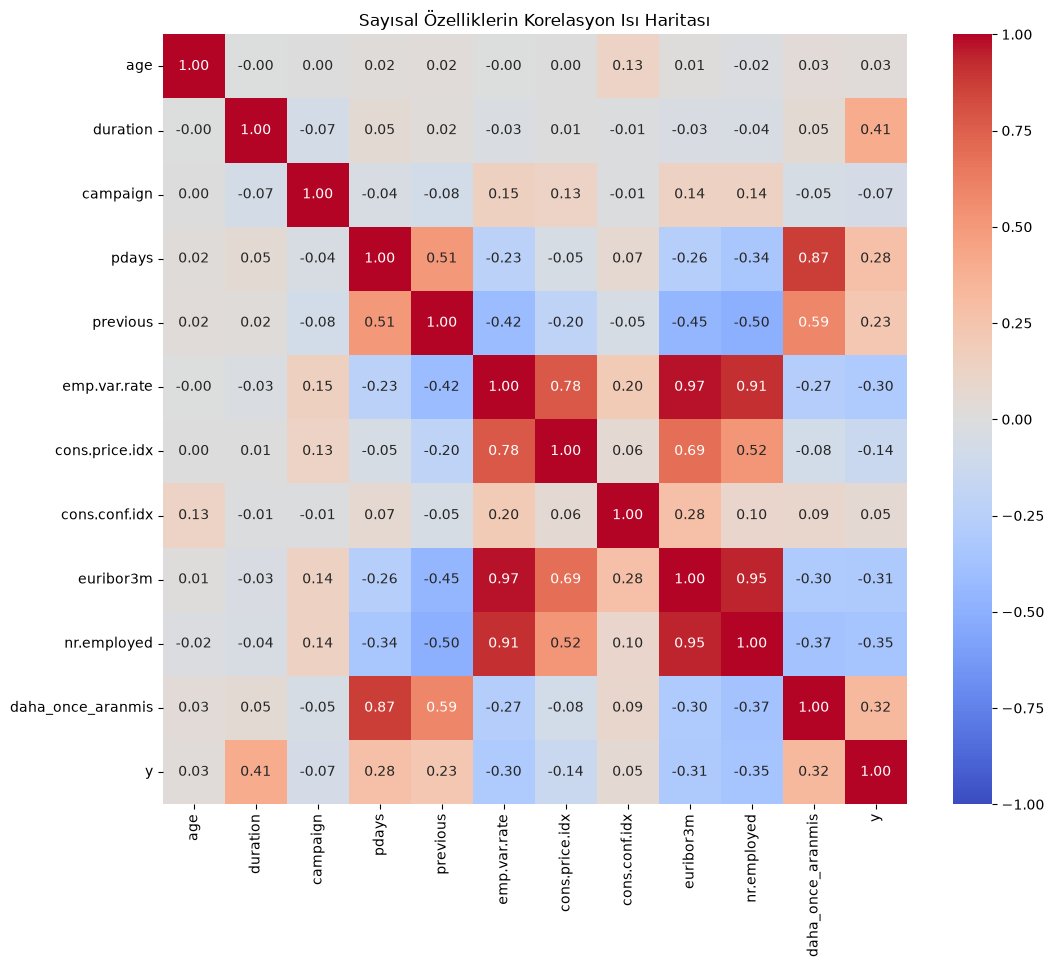

Yüksek Korelasyonlu Sütun Çiftleri (|r| > 0.8):
pdays - daha_once_aranmis: 0.87
emp.var.rate - euribor3m: 0.97
emp.var.rate - nr.employed: 0.91
euribor3m - nr.employed: 0.95

Hedef Değişken (y) ile Korelasyonlar:
duration             0.41
daha_once_aranmis    0.32
pdays                0.28
previous             0.23
cons.conf.idx        0.05
age                  0.03
campaign            -0.07
cons.price.idx      -0.14
emp.var.rate        -0.30
euribor3m           -0.31
nr.employed         -0.35
Name: y, dtype: float64


In [5]:
# 1. Korelasyon hesaplanacak sayısal sütunlar (hedef y dahil)
korelasyon_sutunlari = ['age', 'duration', 'campaign', 'pdays', 'previous',
                        'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
                        'euribor3m', 'nr.employed', 'daha_once_aranmis', 'y']

# 2. Pearson korelasyon matrisinin hesaplanması
korelasyon_matrisi = df[korelasyon_sutunlari].corr()

# 3. Korelasyon ısı haritası
plt.figure(figsize=(12, 10))
sns.heatmap(korelasyon_matrisi, annot=True,
            fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1)
plt.title("Sayısal Özelliklerin Korelasyon Isı Haritası")
plt.savefig("figures/c4_korelasyon_isi_haritasi.png", dpi=150, bbox_inches='tight')
plt.show()

# 4. Birbirine çok bağlı sütun çiftleri (|r| > 0.8)
print("Yüksek Korelasyonlu Sütun Çiftleri (|r| > 0.8):")
for i in range(len(korelasyon_sutunlari)):
    for j in range(i + 1, len(korelasyon_sutunlari)):
        r = korelasyon_matrisi.iloc[i, j]
        if abs(r) > 0.8:
            print(f"{korelasyon_sutunlari[i]} - {korelasyon_sutunlari[j]}: {r:.2f}")

# 5. Hedef değişken (y) ile korelasyonlar
print("\nHedef Değişken (y) ile Korelasyonlar:")
print(korelasyon_matrisi['y'].drop('y').sort_values(ascending=False).round(2))

**Yorum:** Üç ekonomik gösterge (emp.var.rate, euribor3m, nr.employed) birbiriyle çok yüksek korelasyonludur (r = 0,91-0,97). Yani üçü de ekonominin genel durumunu ölçüyor ve neredeyse aynı bilgiyi taşıyor (çoklu doğrusal bağlantı). Bu durum lojistik regresyon gibi doğrusal modelleri etkileyebilir; XGBoost gibi ağaç tabanlı modeller ise bundan pek etkilenmez. pdays ile daha_once_aranmis arasındaki 0,87'lik ilişki beklenen bir sonuçtur, çünkü ikinci sütun birinciden türetilmiştir. Hedefle en güçlü ilişki duration'dadır (+0,41), ancak bu sütun veri sızıntısı nedeniyle modelden çıkarılmıştır. Ekonomik göstergeler hedefle negatif ilişkilidir (yaklaşık −0,30), yani ekonomik göstergeler düşükken müşteriler daha çok mevduat açmıştır. Korelasyon yalnızca doğrusal ilişkiyi ölçtüğü için düşük değerler, o özelliğin model için önemsiz olduğu anlamına gelmez

## C5. Scatter plot'lar

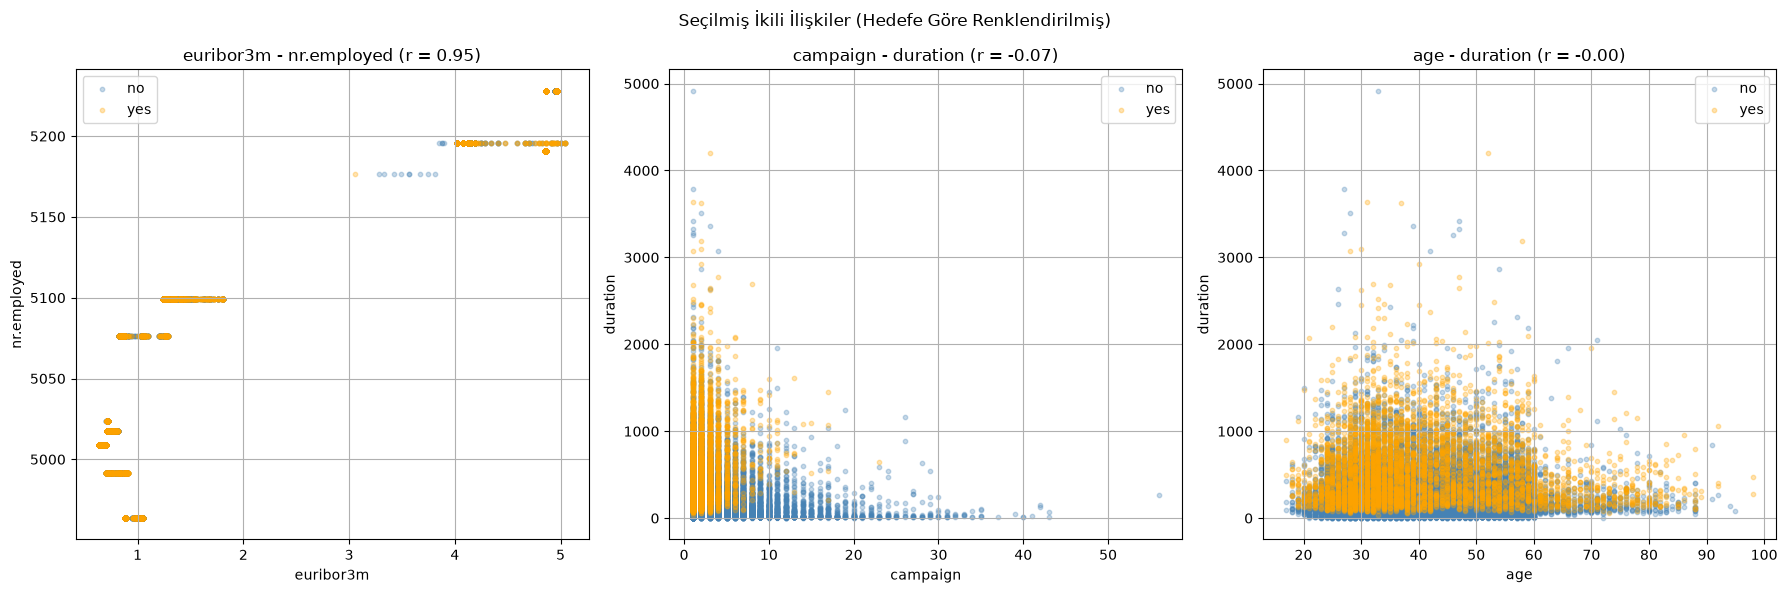

In [6]:
# 1. İncelenecek ikili ilişkiler (x ekseni, y ekseni)
sutun_ciftleri = [('euribor3m', 'nr.employed'),
                  ('campaign', 'duration'),
                  ('age', 'duration')]
sinif_adlari = ['no', 'yes']
renkler = ['steelblue', 'orange']

# 2. Her çift için hedefe göre renklendirilmiş scatter plot
plt.figure(figsize=(18, 6))
for i, (x_sutun, y_sutun) in enumerate(sutun_ciftleri):
    plt.subplot(1, 3, i + 1)
    for sinif in range(len(sinif_adlari)):
        plt.scatter(df.loc[df['y'] == sinif, x_sutun],
                    df.loc[df['y'] == sinif, y_sutun],
                    label=sinif_adlari[sinif], color=renkler[sinif],
                    alpha=0.3, s=10)
    r = df[x_sutun].corr(df[y_sutun])
    plt.title(f"{x_sutun} - {y_sutun} (r = {r:.2f})")
    plt.xlabel(x_sutun)
    plt.ylabel(y_sutun)
    plt.legend()
    plt.grid(True)
plt.suptitle("Seçilmiş İkili İlişkiler (Hedefe Göre Renklendirilmiş)")
plt.tight_layout()
plt.savefig("figures/c5_scatter_plotlar.png", dpi=150, bbox_inches='tight')
plt.show()

**Yorum:** euribor3m – nr.employed: Noktalar sürekli bir bulut değil, ayrı kümeler oluşturuyor. Bunun nedeni bu değerlerin müşteriye göre değil döneme göre değişen ekonomik göstergeler olmasıdır. "yes" müşterileri düşük faiz (euribor < 2) kümelerinde yoğunlaşıyor: bu bölgede "yes" oranı %24,5, diğerlerinde %4,8.
campaign – duration: Aynı müşteri ne kadar çok aranırsa görüşmeler o kadar kısalıyor ve "yes" azalıyor. 10'dan fazla aranan müşterilerde "yes" oranı yalnızca %3; 23'ten fazla aranıp "yes" diyen hiç müşteri yok.
age – duration: Yaş ile görüşme süresi arasında doğrusal ilişki yok (r = 0,00). Ancak 60 yaş üstü müşterilerde "yes" oranı %45,5'e çıkıyor; bu, C3'teki emekliler bulgusuyla tutarlı.